# Monte Carlo simulation: OLS inference under heteroskedasticity

Repeated samples from a known model let us assess how OLS estimates vary and
how often confidence intervals contain the true coefficient. The analysis compares
**conventional, HC1 and HC3 standard errors** for sample sizes of 250 and 1,000,
using 10,000 replications for each size.

Data are generated within the notebook; no external dataset is needed.
The observations are independent, so the analysis concerns heteroskedasticity,
rather than serial correlation.

## Environment setup

**Colab:** the setup expects the complete `Notebooks` folder in **My Drive**,
with its subfolders and CSV files. Running the cell below mounts Google Drive
and requests access.
**Local Jupyter:** the same folder structure supports local execution.
`NOTEBOOKS_ROOT` specifies a different location when needed.


In [1]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "OLS"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder found: {DATA_DIR.name}")

Data folder found: OLS


## Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from IPython.display import display

## Data-generating process

The population model is

$$y_i=\beta_0+\beta_1x_i+u_i,\qquad \beta_0=1,\quad \beta_1=0.5,$$

$$x_i\sim N(1,2),\qquad U_i\sim\operatorname{Uniform}(-3,3),
\qquad u_i=U_i\sqrt{4+x_i^2}.$$

The Normal distribution has **mean 1 and variance 2**. $U_i$ is independent
of $x_i$, and observations are independent and identically distributed across $i$.
Since $E[U_i]=0$ and $\operatorname{Var}(U_i)=3$,

$$E[u_i\mid x_i]=0,\qquad \operatorname{Var}(u_i\mid x_i)=3(4+x_i^2).$$

Thus OLS is unbiased, but errors are heteroskedastic: their conditional
variance increases with $|x_i|$. Conditional errors are uniform, not Normal;
zero conditional mean and constant variance are separate assumptions.

In [3]:
BETA_0 = 1.0
BETA_1 = 0.5
SAMPLE_SIZES = (250, 1_000)
REPLICATIONS = 10_000
ALPHA = 0.05
SEED = 2026
METHODS = ("Conventional", "HC1", "HC3")

def generate_sample(n, rng):
    # NumPy takes the standard deviation, not the variance, as scale.
    x = rng.normal(loc=1.0, scale=np.sqrt(2.0), size=n)
    U = rng.uniform(low=-3.0, high=3.0, size=n)
    u = U * np.sqrt(4.0 + x**2)
    y = BETA_0 + BETA_1 * x + u
    return x, y, u

# A separate random stream keeps the illustration independent of the experiment.
x_example, y_example, u_example = generate_sample(
    500, np.random.default_rng(np.random.SeedSequence([SEED, 0]))
)
display(pd.DataFrame({"x": x_example, "y": y_example, "u": u_example}).head().round(3))

,x,y,u
0,-0.122,3.538,2.598
1,1.340,7.623,5.952
2,-1.682,6.847,6.688
3,2.974,4.351,1.864
4,1.903,-0.491,-2.443


### One simulated sample

The line below is the **true conditional mean**, not an estimated regression.
The dashed curves are one conditional standard deviation above and below it;
they are not confidence intervals. Dispersion is smallest near zero and grows
in both directions. A single sample illustrates the model; repeated samples
are needed to evaluate inference.

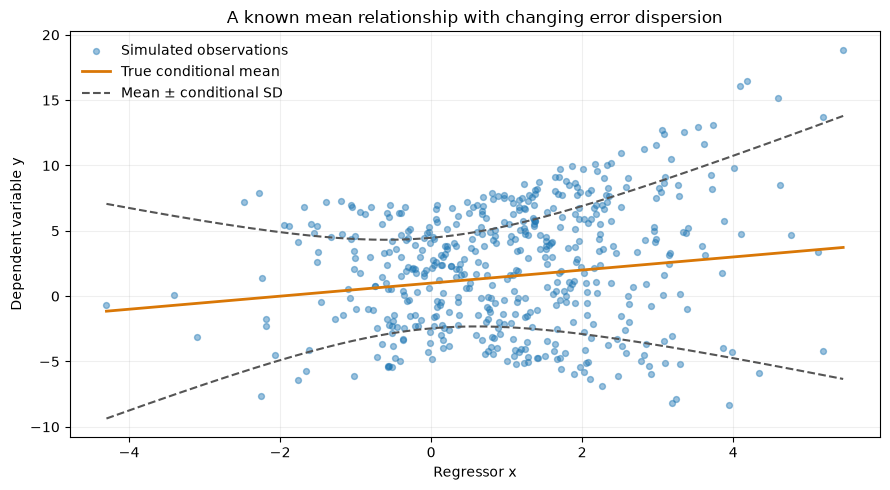

In [4]:
x_grid = np.linspace(x_example.min(), x_example.max(), 250)
true_mean = BETA_0 + BETA_1 * x_grid
conditional_sd = np.sqrt(3.0 * (4.0 + x_grid**2))

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(x_example, y_example, s=18, alpha=0.45, color="#1f77b4",
           label="Simulated observations")
ax.plot(x_grid, true_mean, color="#d97706", linewidth=2,
        label="True conditional mean")
ax.plot(x_grid, true_mean + conditional_sd, color="#555555", linestyle="--",
        label="Mean ± conditional SD")
ax.plot(x_grid, true_mean - conditional_sd, color="#555555", linestyle="--")
ax.set(xlabel="Regressor x", ylabel="Dependent variable y",
       title="A known mean relationship with changing error dispersion")
ax.legend(frameon=False)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Confidence intervals and hypothesis tests

Each replication produces one OLS fit and three standard errors
for the **same slope estimate**. Conventional SEs assume constant variance.
HC1 uses a heteroskedasticity-robust covariance with a degrees-of-freedom
correction, $n/(n-2)$. HC3 adjusts each squared residual for leverage using
$\widehat u_i^2/(1-h_{ii})^2$, where $h_{ii}$ is its leverage.

All methods use the same $t_{n-2}$ reference:

$$\widehat\beta_1\ \pm\ t_{n-2,\,1-\alpha/2}\,\widehat{SE}(\widehat\beta_1),
\qquad \alpha=0.05.$$

This reference is approximate here: the errors are not Normal, and robust
inference is justified asymptotically. Using the same reference isolates
the difference between the covariance estimators.

Each test compares $H_0:\beta_1=0.5$ with $H_1:\beta_1\ne0.5$. The null is **true** in this
experiment. The nominal significance level is 5%; a Type I error occurs when
we reject this true null. A Type II error means failing to reject a false null;
its probability depends on the alternative and is not measured here.

In [5]:
def run_monte_carlo(n, replications, seed):
    rng = np.random.default_rng(np.random.SeedSequence([seed, n]))
    critical_value = stats.t.ppf(1.0 - ALPHA / 2.0, df=n - 2)
    records = []

    for replication in range(replications):
        x, y, _ = generate_sample(n, rng)
        X = sm.add_constant(x)
        ols = sm.OLS(y, X).fit()
        estimates = {
            "Conventional": ols,
            "HC1": ols.get_robustcov_results(cov_type="HC1", use_t=True),
            "HC3": ols.get_robustcov_results(cov_type="HC3", use_t=True),
        }

        for method, result in estimates.items():
            slope = float(result.params[1])
            se = float(result.bse[1])
            lower = slope - critical_value * se
            upper = slope + critical_value * se
            # Test the true slope, not zero: rejection measures Type I error.
            t_statistic = (slope - BETA_1) / se
            p_value = 2.0 * stats.t.sf(abs(t_statistic), df=n - 2)
            records.append({
                "n": n, "Replication": replication + 1, "Method": method,
                "Slope": slope, "SE": se, "Lower": lower, "Upper": upper,
                "Covered": lower <= BETA_1 <= upper,
                "Rejected": p_value < ALPHA,
            })

    return pd.DataFrame(records)

results = pd.concat(
    [run_monte_carlo(n, REPLICATIONS, SEED) for n in SAMPLE_SIZES],
    ignore_index=True
)
print(f"Completed {REPLICATIONS:,} replications for each n in {SAMPLE_SIZES}.")

Completed 10,000 replications for each n in (250, 1000).


## The sampling distribution of the OLS slope

The mean slope across replications approximates its expected value. Its
standard deviation is the **empirical sampling SD**: it measures actual
variation across independent samples. A standard error estimates this
uncertainty from just one sample.

OLS is unbiased in this model, so the mean estimate should be close to 0.5;
it need not equal 0.5 in a finite simulation. Increasing the sample size should
reduce the sampling spread. Changing the SE method does not change any
OLS slope estimate.

,Mean slope,Empirical SD,Estimated bias,MC SE of mean
n,,,,
250,0.5002,0.2551,0.0002,0.0026
1000,0.5006,0.1263,0.0006,0.0013


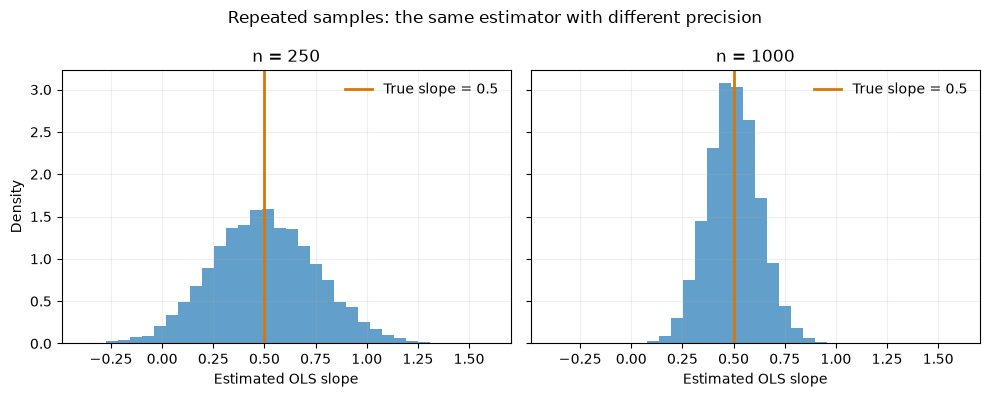

In [6]:
# Keep one slope per replication: the three covariance methods share it.
slopes = results.loc[results["Method"] == "Conventional"]
sampling = slopes.groupby("n").agg(
    Mean_slope=("Slope", "mean"),
    Empirical_SD=("Slope", "std"),
)
sampling["Estimated bias"] = sampling["Mean_slope"] - BETA_1
sampling["MC SE of mean"] = sampling["Empirical_SD"] / np.sqrt(REPLICATIONS)
sampling = sampling.rename(columns={"Mean_slope": "Mean slope",
                                    "Empirical_SD": "Empirical SD"})
display(sampling.round(4))

bins = np.linspace(slopes["Slope"].min(), slopes["Slope"].max(), 35)
fig, axes = plt.subplots(1, len(SAMPLE_SIZES), figsize=(10, 4),
                         sharex=True, sharey=True, squeeze=False)
for ax, n in zip(axes.flat, SAMPLE_SIZES):
    values = slopes.loc[slopes["n"] == n, "Slope"]
    ax.hist(values, bins=bins, density=True, color="#1f77b4", alpha=0.7)
    ax.axvline(BETA_1, color="#d97706", linewidth=2, label="True slope = 0.5")
    ax.set(title=f"n = {n}", xlabel="Estimated OLS slope")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
axes[0, 0].set_ylabel("Density")
fig.suptitle("Repeated samples: the same estimator with different precision")
fig.tight_layout()
plt.show()

## Coverage and rejection rates

**Coverage** is the fraction of simulated intervals containing the true slope:

$$\widehat{\text{Coverage}}=
\frac{1}{M}\sum_{m=1}^{M}
\mathbf{1}\{L_m\le 0.5\le U_m\}.$$

The target is 95%. This describes the interval procedure over repeated samples;
after an interval is computed, the fixed true coefficient either lies inside
it or does not. The **rejection rate** is the fraction of tests rejecting
the true null; its target is 5%. For these matching two-sided tests and intervals,
rejection rate equals one minus coverage.

Comparing the average estimated SE with the empirical sampling SD shows how closely estimated uncertainty tracks actual sampling variation. Intervals
that are too narrow tend to under-cover and over-reject. Interval width matters
alongside coverage: making an interval extremely wide can increase coverage
without providing precise inference.

In [7]:
summary = results.assign(Width=results["Upper"] - results["Lower"]).groupby(
    ["n", "Method"], sort=False
).agg(
    Mean_SE=("SE", "mean"),
    Mean_width=("Width", "mean"),
    Coverage=("Covered", "mean"),
    Rejection=("Rejected", "mean"),
)
summary["Empirical SD"] = summary.index.get_level_values("n").map(
    sampling["Empirical SD"]
)
summary["Mean SE / empirical SD"] = summary["Mean_SE"] / summary["Empirical SD"]
# Monte Carlo uncertainty of an estimated proportion from M independent samples.
summary["MC SE"] = np.sqrt(summary["Coverage"] * (1.0 - summary["Coverage"])
                            / REPLICATIONS)

comparison = summary.rename(columns={"Mean_SE": "Mean SE", "Mean_width": "Mean CI width"})
comparison = comparison[["Empirical SD", "Mean SE", "Mean SE / empirical SD",
                         "Mean CI width", "Coverage", "Rejection", "MC SE"]].copy()
comparison[["Coverage", "Rejection", "MC SE"]] *= 100.0
comparison = comparison.rename(columns={"Coverage": "Coverage (%)",
                                       "Rejection": "Rejection (%)",
                                       "MC SE": "MC SE (pp)"})
display(comparison.round(3))

Empirical SD  Mean SE  Mean SE / empirical SD  \
n    Method                                                        
250  Conventional         0.255    0.205                   0.804   
     HC1                  0.255    0.254                   0.994   
     HC3                  0.255    0.258                   1.010   
1000 Conventional         0.126    0.103                   0.812   
     HC1                  0.126    0.128                   1.014   
     HC3                  0.126    0.129                   1.018   

                   Mean CI width  Coverage (%)  Rejection (%)  MC SE (pp)  
n    Method                                                                
250  Conventional          0.808         88.26          11.74       0.322  
     HC1                   0.999         94.52           5.48       0.228  
     HC3                   1.015         94.88           5.12       0.220  
1000 Conventional          0.402         88.87          11.13       0.315  
     HC1                   0.503         95.05           4.95       0.217  
     HC3                   0.505         95.16           4.84       0.215

### Accounting for simulation uncertainty

With 10,000 replications, a coverage estimate near 95% has a Monte Carlo SE of
about **0.22 percentage points**. The error bars below show approximately
±1.96 Monte Carlo SEs around each estimated coverage. They describe uncertainty
in the simulation result, not uncertainty in a regression coefficient.

The three SE methods use the same simulated samples, so their results are paired.
These separate error bars are not a formal test of differences between methods.
Small departures from 95%, or small changes between sample sizes, can reflect
simulation noise. Increasing replications reduces this noise; increasing sample
size changes the statistical performance of the regression procedure.

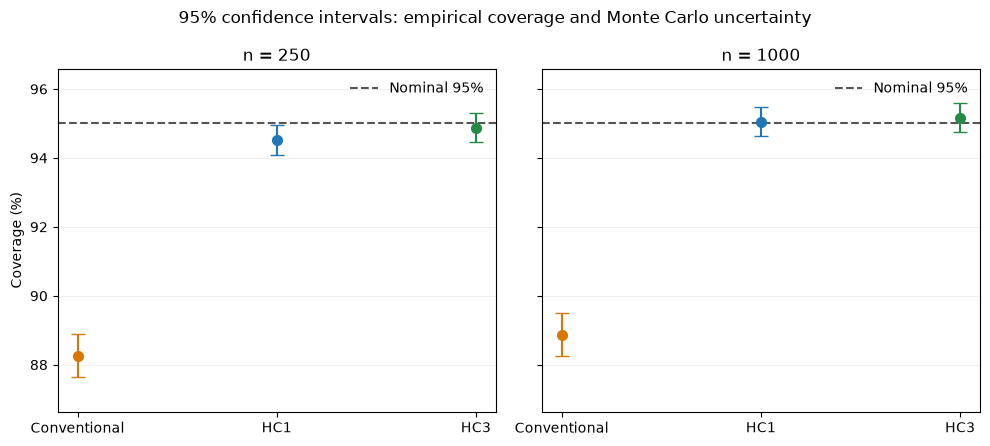

In [8]:
fig, axes = plt.subplots(1, len(SAMPLE_SIZES), figsize=(10, 4.5),
                         sharey=True, squeeze=False)
colors = ("#d97706", "#1f77b4", "#238b45")
lowest = 100.0 * (summary["Coverage"] - 1.96 * summary["MC SE"]).min()
highest = 100.0 * (summary["Coverage"] + 1.96 * summary["MC SE"]).max()
for ax, n in zip(axes.flat, SAMPLE_SIZES):
    for position, (method, color) in enumerate(zip(METHODS, colors)):
        row = summary.loc[(n, method)]
        ax.errorbar(position, 100.0 * row["Coverage"],
                    yerr=100.0 * 1.96 * row["MC SE"],
                    fmt="o", color=color, capsize=5, markersize=7)
    ax.axhline(95.0, color="#555555", linestyle="--", label="Nominal 95%")
    ax.set_xticks(range(len(METHODS)), METHODS)
    ax.set(title=f"n = {n}", ylim=(min(lowest - 1.0, 93.0), max(highest + 1.0, 96.0)))
    ax.grid(axis="y", alpha=0.2)
    ax.legend(frameon=False)
axes[0, 0].set_ylabel("Coverage (%)")
fig.suptitle("95% confidence intervals: empirical coverage and Monte Carlo uncertainty")
fig.tight_layout()
plt.show()

## Interpreting the experiment

The slope estimates remain centred near the true value, while their sampling
spread decreases in the larger sample. Heteroskedasticity affects the
conventional variance estimate, rather than unbiasedness in this model.

Here conventional SEs understate sampling uncertainty, producing intervals
with coverage below 95% and rejection rates above 5%. HC1 and HC3 account for
the changing error variance. HC3's leverage adjustment generally produces
wider intervals than HC1 here; this does not make HC3 universally preferable.

Robust inference is asymptotically valid under the assumptions of this experiment,
but exact 95% coverage is not guaranteed in finite samples. Results need not
improve monotonically as sample size increases. More replications
estimate coverage more precisely; they do not improve the interval procedure
at a fixed sample size. Asymptotic validity concerns increasing the number of
observations per sample, rather than the number of replications. The simulated
outcomes depend on this DGP, sample size and number of replications; they are
not a universal ranking of SE methods. HC1 and HC3 do not correct endogeneity
and rely on independent observations in this experiment.